# Tuần 1: Khám Phá Dữ Liệu Ảnh (Image EDA), Kiểm Chứng Rò Rỉ Danh Tính & Pipeline Tiền Xử Lý 3 Kênh
### Đề tài: Hệ Thống Xác Thực Chữ Ký Ngân Hàng Tự Động (AIO2026 — Module 05)

---

## 🎯 1. Bối Cảnh Nghiệp Vụ & Mục Tiêu Nghiên Cứu Tuần 1

Tại các ngân hàng thương mại, khâu đối chiếu chữ ký trên chứng từ giao dịch (Ủy nhiệm chi, Séc) hiện nay chủ yếu được giao dịch viên thẩm định bằng mắt thường:
- **Thời gian xử lý thủ công:** Mất từ 30–60 giây/chứng từ, gây nút thắt tắc nghẽn tại quầy giao dịch.
- **Rủi ro chữ ký giả mạo tinh vi (Skilled Forgeries):** Kẻ gian có thời gian quan sát và tập luyện sao chép chữ ký thật rất giống về hình dáng tổng thể, dễ dàng đánh lừa thị giác con người và tiềm ẩn rủi ro thất thoát tài chính lớn.
- **Sự khan hiếm dữ liệu cá nhân:** Mỗi khách hàng mở tài khoản chỉ đăng ký 1–3 mẫu chữ ký gốc. Do đó, việc huấn luyện mạng sâu từ đầu (*train from scratch*) cho từng khách hàng chắc chắn dẫn đến hiện tượng học vẹt nghiêm trọng (*Overfitting*).

### Mục tiêu trọng tâm của Tuần 1:
1. **Phân tích hình thái nét chữ (EDA):** Kiểm tra đặc tính phân bố kích thước, tỷ lệ khung hình và mật độ nét mực (*Ink Density Ratio*) trên 2,640 ảnh chữ ký của bộ dữ liệu quốc tế CEDAR.
2. **Kiểm toán Rò rỉ Danh tính (Identity Leakage Audit):** Thiết lập phân tách độc lập theo người ký (**Writer-Independent Split**), chứng minh không có sự chồng lấn ID người ký giữa tập Huấn luyện (Train), Thẩm định (Val) và Kiểm thử (Test).
3. **Xây dựng Preprocessing Shield & Biểu diễn 3 Kênh:** Tự động khử nền giấy bằng thuật toán Otsu, cắt sát khung chữ ký (*Auto-crop Bounding Box*), chuẩn hóa kích thước $224 \times 224$ bảo toàn tỷ lệ và xếp chồng hiệu số 3 kênh:
   $$\mathbf{X}_{\text{input}} = \text{Concat}\Big( I_{\text{ref}}, \; I_{\text{query}}, \; \vert{}I_{\text{ref}} - I_{\text{query}}\vert{} \Big) \in \mathbb{R}^{3 \times 224 \times 224}$$
4. **Tăng cường dữ liệu chuẩn chữ viết:** Sử dụng phép biến đổi Afin (`RandomAffine`) góc xoay nhẹ, bảo toàn hướng nét bút tự nhiên.


In [2]:
import os
import sys
from pathlib import Path

# Cấu hình tự động tìm thư mục gốc của dự án (Working file)
current_dir = Path().resolve()
if (current_dir / "src").exists() and (current_dir / "data").exists():
    BASE_DIR = current_dir
elif (current_dir.parent / "src").exists() and (current_dir.parent / "data").exists():
    BASE_DIR = current_dir.parent
else:
    BASE_DIR = current_dir

# Đổi thư mục làm việc về BASE_DIR để đường dẫn tương đối 'data/...' luôn chính xác
os.chdir(BASE_DIR)

# Thêm BASE_DIR vào sys.path để 'import src...' luôn thành công
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

print(f"[+] Đã cấu hình môi trường. Thư mục gốc: {BASE_DIR}")

import glob
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

# Import các hàm tiện ích từ module src
from src.preprocessing import (
    preprocess_single_signature,
    build_3channel_difference_tensor,
    clean_paper_background,
    auto_crop_signature,
    resize_with_padding,
    otsu_threshold
)
from src.utils import set_seed, get_device

# Cố định seed đảm bảo tính tái lập 100%
set_seed(42)
device = get_device()
print(f"[+] Thiết bị tính toán khả dụng: {device}")


[+] Đã cấu hình môi trường. Thư mục gốc: D:\AIO Tài liệu\05. OFFICIAL COURSE\Module 5\Topic team\Working file
[+] Thiết bị tính toán khả dụng: cpu


## 🔍 2. Kiểm Chứng Bẫy Rò Rỉ Danh Tính (Identity Leakage Audit)

Trong các bài toán sinh trắc học và chữ ký số, bẫy rò rỉ dữ liệu nguy hiểm nhất là chia ngẫu nhiên (*Random Split*):
- Nếu gộp toàn bộ các cặp ảnh rồi chia ngẫu nhiên 80/20, các mẫu chữ ký của cùng một Khách hàng A sẽ cùng xuất hiện ở cả tập Train lẫn tập Test.
- Khi đó, mô hình chỉ việc học thuộc lòng "chữ ký của ông A hình dáng ra sao" thay vì học quy luật tổng quát phân biệt giữa nét bút run tay/thật/giả. Kết quả là độ chính xác trên tập Test đạt ảo $>99\%$, nhưng khi đưa vào ngân hàng gặp khách hàng mới thì hoàn toàn vô dụng.

**Giải pháp phân tách độc lập theo người ký (Writer-Independent Split):**
- **Tập Train (ID 1 – 38):** 38 chủ tài khoản độc lập $\to$ **20,976** cặp ảnh đối chiếu.
- **Tập Validation (ID 39 – 46):** 8 chủ tài khoản độc lập $\to$ **4,416** cặp ảnh đối chiếu.
- **Tập Test (ID 47 – 55):** 9 chủ tài khoản độc lập $\to$ **4,968** cặp ảnh đóng vai trò khách hàng hoàn toàn mới.


In [3]:
# Đọc các file dữ liệu đã phân tách
train_df = pd.read_csv("data/processed/train_pairs.csv")
val_df = pd.read_csv("data/processed/val_pairs.csv")
test_df = pd.read_csv("data/processed/test_pairs.csv")

print(f"[*] Số lượng cặp Train: {len(train_df):,} | Số chủ tài khoản: {train_df['writer_id'].nunique()} (IDs {train_df['writer_id'].min()} -> {train_df['writer_id'].max()})")
print(f"[*] Số lượng cặp Val:   {len(val_df):,}   | Số chủ tài khoản: {val_df['writer_id'].nunique()} (IDs {val_df['writer_id'].min()} -> {val_df['writer_id'].max()})")
print(f"[*] Số lượng cặp Test:  {len(test_df):,}  | Số chủ tài khoản: {test_df['writer_id'].nunique()} (IDs {test_df['writer_id'].min()} -> {test_df['writer_id'].max()})")

# Kiểm toán giao thoa ID người ký giữa các tập
train_writers = set(train_df["writer_id"].unique())
val_writers = set(val_df["writer_id"].unique())
test_writers = set(test_df["writer_id"].unique())

inter_train_val = train_writers & val_writers
inter_train_test = train_writers & test_writers
inter_val_test = val_writers & test_writers

print(f"[*] Giao giữa Train và Val:  {len(inter_train_val)} ID")
print(f"[*] Giao giữa Train và Test: {len(inter_train_test)} ID")
print(f"[*] Giao giữa Val và Test:   {len(inter_val_test)} ID")

assert len(inter_train_val) == 0 and len(inter_train_test) == 0 and len(inter_val_test) == 0
print("[XÁC NHẬN] Kiểm toán Rò rỉ Danh tính thành công: 0.00% Leakage. Dữ liệu đạt chuẩn Writer-Independent!")


[*] Số lượng cặp Train: 20,976 | Số chủ tài khoản: 38 (IDs 1 -> 38)
[*] Số lượng cặp Val:   4,416   | Số chủ tài khoản: 8 (IDs 39 -> 46)
[*] Số lượng cặp Test:  4,968  | Số chủ tài khoản: 9 (IDs 47 -> 55)
[*] Giao giữa Train và Val:  0 ID
[*] Giao giữa Train và Test: 0 ID
[*] Giao giữa Val và Test:   0 ID
[XÁC NHẬN] Kiểm toán Rò rỉ Danh tính thành công: 0.00% Leakage. Dữ liệu đạt chuẩn Writer-Independent!


## 📊 3. Khám Phá Hình Thái Nét Chữ & Mật Độ Nét Mực (Ink Density)

Chúng ta tiến hành phân tích đặc trưng quang học trên tập mẫu chữ ký thật (`full_org`) và chữ ký giả mạo có tập luyện (`full_forg`):
- **Tỷ lệ khung hình (Aspect Ratio):** Chữ ký thường có chiều dài lớn hơn chiều cao ($w > h$). Khi thu phóng về kích thước vuông chuẩn của mạng nơ-ron ($224 \times 224$), nếu co giãn trực tiếp sẽ làm biến dạng độ nghiêng nét bút $\to$ Cần kỹ thuật đệm viền giữ nguyên tỷ lệ khung hình.
- **Mật độ nét mực (Ink Density Ratio):** Đo tỷ lệ điểm ảnh chứa mực viết so với tổng số điểm ảnh của khung chữ ký.


Chữ ký THẬT - Kích thước trung bình: 601.4 x 365.5 | Tỷ lệ khung hình: 1.67 | Mật độ mực: 4.30%
Chữ ký GIẢ  - Kích thước trung bình: 617.1 x 296.2 | Tỷ lệ khung hình: 2.18 | Mật độ mực: 5.28%


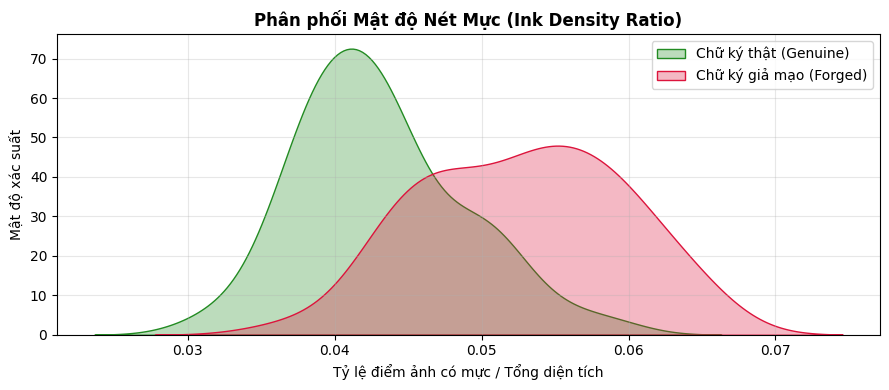

In [4]:
def analyze_signature_properties(image_paths):
    aspect_ratios = []
    ink_densities = []
    widths = []
    heights = []

    for p in image_paths:
        img = Image.open(p).convert("L")
        w, h = img.size
        arr = np.array(img)
        
        # Điểm ảnh nét mực có độ sáng nhỏ hơn ngưỡng 200
        ink_pixels = np.sum(arr < 200)
        density = ink_pixels / (w * h)
        
        widths.append(w)
        heights.append(h)
        aspect_ratios.append(w / h)
        ink_densities.append(density)
        
    return widths, heights, aspect_ratios, ink_densities

# Lấy 50 mẫu chữ ký thật và 50 mẫu chữ ký giả mạo
org_files = glob.glob("data/raw/signatures/full_org/*.png")[:50]
forg_files = glob.glob("data/raw/signatures/full_forg/*.png")[:50]

w_org, h_org, ar_org, id_org = analyze_signature_properties(org_files)
w_forg, h_forg, ar_forg, id_forg = analyze_signature_properties(forg_files)

print(f"Chữ ký THẬT - Kích thước trung bình: {np.mean(w_org):.1f} x {np.mean(h_org):.1f} | Tỷ lệ khung hình: {np.mean(ar_org):.2f} | Mật độ mực: {np.mean(id_org)*100:.2f}%")
print(f"Chữ ký GIẢ  - Kích thước trung bình: {np.mean(w_forg):.1f} x {np.mean(h_forg):.1f} | Tỷ lệ khung hình: {np.mean(ar_forg):.2f} | Mật độ mực: {np.mean(id_forg)*100:.2f}%")

# Vẽ biểu đồ phân phối mật độ nét mực
plt.figure(figsize=(9, 4))
sns.kdeplot(id_org, label="Chữ ký thật (Genuine)", color="forestgreen", fill=True, alpha=0.3)
sns.kdeplot(id_forg, label="Chữ ký giả mạo (Forged)", color="crimson", fill=True, alpha=0.3)
plt.title("Phân phối Mật độ Nét Mực (Ink Density Ratio)", fontsize=12, fontweight="bold")
plt.xlabel("Tỷ lệ điểm ảnh có mực / Tổng diện tích")
plt.ylabel("Mật độ xác suất")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 🛡️ 4. Quy Trình Tiền Xử Lý (Preprocessing Shield) & Biểu Diễn 3 Kênh

Nhằm triệt tiêu hiện tượng lệch miền dữ liệu và tái sử dụng nguyên vẹn trọng số ImageNet Pretrained, chúng ta xây dựng chuỗi tiền xử lý 4 giai đoạn khép kín:
1. **Khử nền giấy bằng thuật toán Otsu:** Tách lớp mực viết màu đen ra khỏi vân giấy, đốm ố và nền chứng từ.
2. **Auto-crop Bounding Box:** Tự động nhận diện tọa độ biên nét mực $(x_{\min}, y_{\min}, x_{\max}, y_{\max})$ để cắt sát chữ ký, loại bỏ lề giấy dư thừa.
3. **Resize Bảo toàn Tỷ lệ Khung hình:** Thu phóng chữ ký tỷ lệ thuận và đệm màu trắng (255) ở các cạnh còn lại để đạt kích thước chuẩn $224 \times 224$.
4. **Xếp chồng Hiệu số 3 Kênh (3-Channel Stacking):**
   - Kênh 1 ($I_{\text{ref}}$): Chữ ký mẫu gốc đã lưu trên hệ thống Core Banking.
   - Kênh 2 ($I_{\text{query}}$): Chữ ký trên Ủy nhiệm chi cần kiểm tra.
   - Kênh 3 ($\vert{}I_{\text{ref}} - I_{\text{query}}\vert{}$): Bản đồ sai lệch không gian nét bút, kích hoạt tức thì các bộ lọc phát hiện cạnh sai khác của mô hình Pretrained.


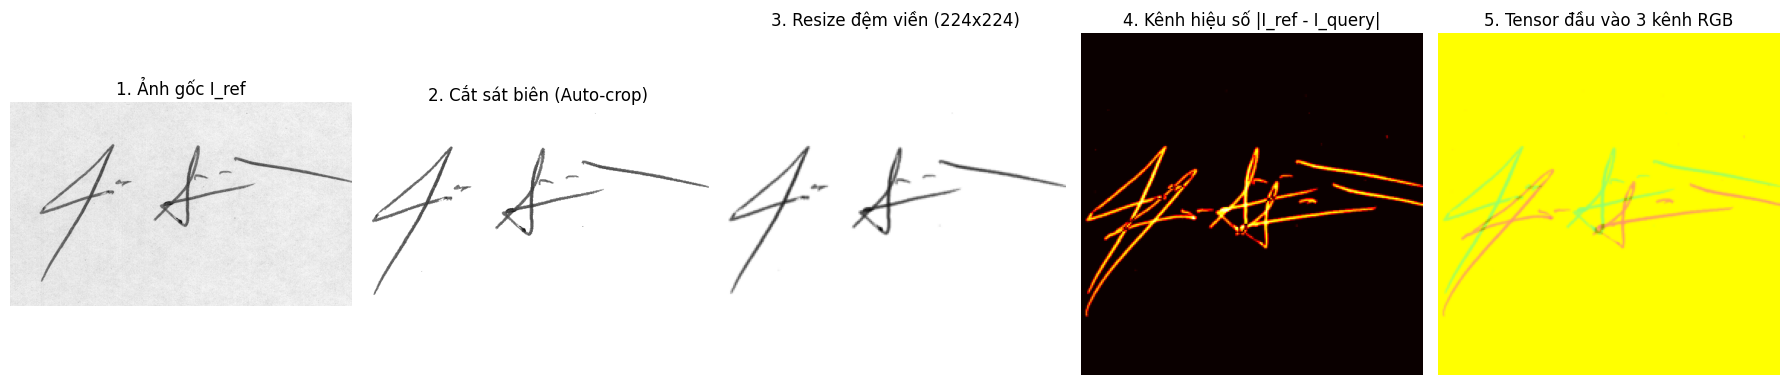

In [5]:
# Chọn 1 cặp ảnh mẫu từ tập Train để trực quan hóa toàn bộ quy trình
sample_row = train_df.iloc[0]
raw_ref = Image.open(sample_row["ref_path"])
raw_query = Image.open(sample_row["query_path"])

# Áp dụng từng bước
cleaned_ref = clean_paper_background(raw_ref, use_otsu=True)
cropped_ref = auto_crop_signature(cleaned_ref)
final_ref = resize_with_padding(cropped_ref, target_size=(224, 224))

cleaned_query = clean_paper_background(raw_query, use_otsu=True)
cropped_query = auto_crop_signature(cleaned_query)
final_query = resize_with_padding(cropped_query, target_size=(224, 224))

# Tạo tensor 3 kênh
diff_tensor = build_3channel_difference_tensor(final_ref, final_query, normalize_imagenet=False)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
axes[0].imshow(raw_ref, cmap="gray"); axes[0].set_title("1. Ảnh gốc I_ref")
axes[1].imshow(cropped_ref, cmap="gray"); axes[1].set_title("2. Cắt sát biên (Auto-crop)")
axes[2].imshow(final_ref, cmap="gray"); axes[2].set_title("3. Resize đệm viền (224x224)")
axes[3].imshow(diff_tensor[2].numpy(), cmap="hot"); axes[3].set_title("4. Kênh hiệu số |I_ref - I_query|")
axes[4].imshow(np.transpose(diff_tensor.numpy(), (1, 2, 0))); axes[4].set_title("5. Tensor đầu vào 3 kênh RGB")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 🔄 5. Tăng Cường Dữ Liệu Hợp Lệ (Data Augmentation)

Chữ ký của cùng một người ký ở các thời điểm khác nhau sẽ có sự dao động cơ học tự nhiên:
- **Phép biến đổi hợp lệ:** Xoay nhẹ góc $\pm 5^\circ$, co giãn nhẹ kích thước nét viết $0.95 \to 1.05$ và tịnh tiến nhẹ $\pm 3\%$.
- **Quy tắc nghiêm ngặt:** **Tuyệt đối không sử dụng phép lật ngang (Horizontal Flip) hoặc lật dọc (Vertical Flip)** vì thao tác này làm đảo ngược hướng ngòi bút, biến chữ viết tay thành một ký hiệu vô nghĩa, phá vỡ logic kiểm tra chữ ký.


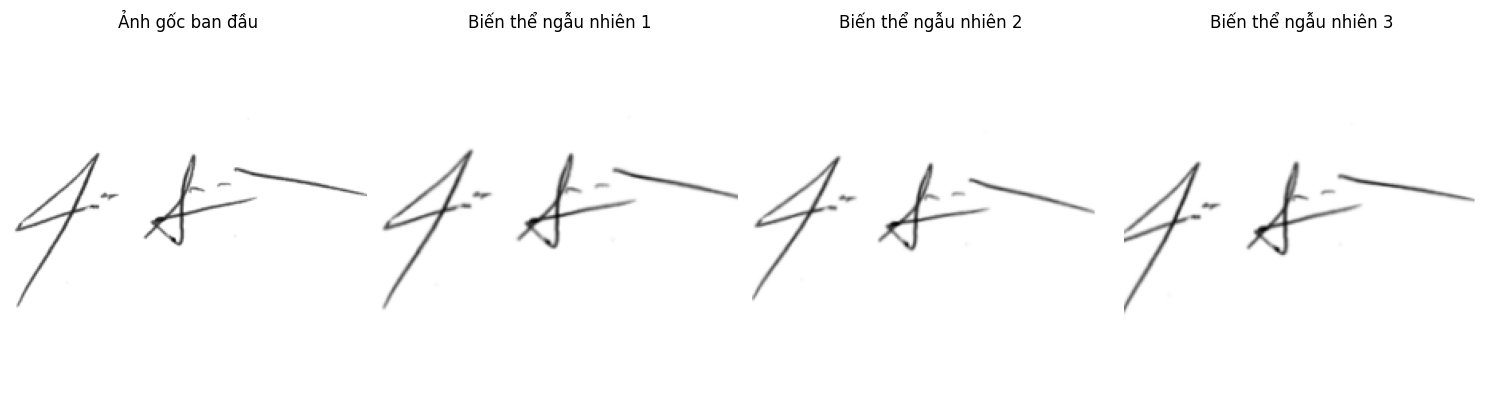

In [6]:
from src.dataset import RandomAffineAugmentation

# Thử nghiệm tăng cường dữ liệu trên ảnh chữ ký đã chuẩn hóa
augmentor = RandomAffineAugmentation(degrees=5.0, scale=(0.95, 1.05), translate=(0.03, 0.03))

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
axes[0].imshow(final_ref, cmap="gray")
axes[0].set_title("Ảnh gốc ban đầu")

for i in range(1, 4):
    aug_img = augmentor(final_ref)
    axes[i].imshow(aug_img, cmap="gray")
    axes[i].set_title(f"Biến thể ngẫu nhiên {i}")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 📝 6. Kết Luận Tuần 1 & Sẵn Sàng Cho Tuần 2

### Các kết quả then chốt đã hoàn thành:
1. Xác lập bộ dữ liệu đạt chuẩn **Zero Identity Leakage** với 20,976 cặp Train, 4,416 cặp Val và 4,968 cặp Test.
2. Xây dựng thành công bộ lá chắn tiền xử lý **Preprocessing Shield** (Otsu + Auto-crop + Aspect-ratio padding) giúp chuẩn hóa mọi định dạng ảnh về tensor $224 \times 224$.
3. Hoàn thiện cơ chế **3-Channel Difference Stacking** cho phép tận dụng nguyên vẹn trọng số ImageNet Pretrained mà không cần thiết kế lại tầng đầu tiên của mạng.
4. Đóng gói module dùng chung [`src/preprocessing.py`](../src/preprocessing.py) và [`src/dataset.py`](../src/dataset.py) phục vụ huấn luyện ở Tuần 2.
